# 01 · Estatísticas do dataset

Estatísticas do Groove MIDI Dataset (GMD) depois do `prepare`, para a seção de dados do artigo.

- **Fontes:** `data/processed/pieces.csv`, `stats.json`, `tokenizer.json` e `train.npz`, mais os MIDIs crus
  de treino em `data/raw/groove/`.
- **Teste:** só entra nas contagens por partição, que vêm de `pieces.csv` e `stats.json`. Toda medida de
  expressividade (desvio, swing, velocity) usa só o treino.
- **Saída:** as figuras ficam também em `results/dataset/`, em PNG.

A lógica vem do pacote `drumgen`. O notebook só agrega e desenha.

In [1]:
import csv
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from symusic.core import ScoreTick

from drumgen.config import PROJECT_ROOT, ExperimentConfig, PieceType, Split, Style
from drumgen.dataset import Corpus, TrainingWindows
from drumgen.metrics import (
    BEATS_PER_BAR,
    SIXTEENTHS_PER_BEAT,
    DrumSample,
    PositionalProfile,
)
from drumgen.prepare import CatalogEntry, Piece, TokenizedSplit
from drumgen.tokenizer import DrumTokenizer

config = ExperimentConfig.from_yaml(PROJECT_ROOT / "configs" / "transformer.yaml")
paths = config.paths
tokenizer = DrumTokenizer.from_file(paths.tokenizer_file)
stats = json.loads(paths.stats_file.read_text())
pieces = Piece.read_csv(paths.pieces_file)
figures_dir = PROJECT_ROOT / "results" / "dataset"
figures_dir.mkdir(parents=True, exist_ok=True)

STYLES = [*Style.evaluated(), Style.OTHER]
EVALUATED = Style.evaluated()
SPLIT_LABELS = {Split.TRAIN: "treino", Split.VAL: "validação", Split.TEST: "teste"}
print(f"{len(pieces)} performances em pieces.csv; config {config.name}; figuras em {figures_dir.relative_to(PROJECT_ROOT)}")

1138 performances em pieces.csv; config transformer; figuras em results/dataset


### Estilo das figuras

Paleta e tinta da casa (as mesmas das figuras do `evaluate`): uma cor por série, na ordem fixa azul, laranja,
verde-água; grade e eixos em linha fina. Larguras de figura no formato ISMIR: uma coluna (3,3 pol.) ou a página
inteira (7 pol.).

In [2]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRIDLINE = "#e1e0d9"
BASELINE = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
SEQUENTIAL_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
DIVERGING = ["#256abf", "#f0efec", "#e34948"]
COLUMN_WIDTH = 3.35
FULL_WIDTH = 7.0
BAR_HEIGHT = 0.62
WASH_ALPHA = 0.12
SAVE_DPI = 200

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.size": 8,
        "axes.titlesize": 9,
        "axes.titlelocation": "left",
        "axes.titlecolor": INK,
        "axes.labelcolor": INK_SECONDARY,
        "axes.edgecolor": BASELINE,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRIDLINE,
        "grid.linewidth": 0.8,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "legend.frameon": False,
        "legend.labelcolor": INK_SECONDARY,
        "lines.linewidth": 2,
        "lines.solid_capstyle": "round",
    }
)


def decimal(value, digits=2):
    return f"{value:.{digits}f}".replace(".", ",")


def thousands(value):
    return f"{int(value):,}".replace(",", ".")


def percent(value, digits=1):
    return f"{decimal(100 * value, digits)}%"


comma_ticks = FuncFormatter(lambda value, _: f"{value:g}".replace(".", ","))
thousand_ticks = FuncFormatter(lambda value, _: thousands(value))


def save(figure, name):
    target = figures_dir / f"{name}.png"
    figure.savefig(target, dpi=SAVE_DPI, bbox_inches="tight")
    return target

## 1. Visão geral

Os números de cabeçalho do dataset, recontados a partir de `pieces.csv` e conferidos contra o `stats.json` e o
spec (491 grooves e 647 viradas em 4/4, 16.708 compassos de groove no treino, ~71,5 tokens por compasso).

In [3]:
grooves = [piece for piece in pieces if piece.type is PieceType.GROOVE]
fills = [piece for piece in pieces if piece.type is PieceType.FILL]
train_grooves = [piece for piece in grooves if piece.split is Split.TRAIN]
content_tokens = sum(piece.n_tokens - 2 for piece in pieces)
total_bars = sum(piece.n_bars for piece in pieces)
tokens_per_bar = content_tokens / total_bars
groove_ids = {piece.id for piece in grooves}
with paths.catalog_file.open(newline="") as file:
    groove_hours = sum(float(row["duration"]) for row in csv.DictReader(file) if row["id"] in groove_ids) / 3600

overview = pd.DataFrame(
    [
        ("performances 4/4 (groove)", len(grooves), stats["totals"]["grooves"]),
        ("performances 4/4 (virada)", len(fills), stats["totals"]["fills"]),
        ("compassos de groove no treino", sum(p.n_bars for p in train_grooves), stats["totals"]["train_groove_bars"]),
        ("tokens de treino", sum(p.n_tokens for p in pieces if p.split is Split.TRAIN), stats["totals"]["train_tokens"]),
        ("tokens por compasso", round(tokens_per_bar, 2), round(stats["tokens_per_bar"], 2)),
        ("tokens por sequência (média)", round(content_tokens / len(pieces), 1), round(stats["mean_tokens_per_sequence"], 1)),
        ("tamanho do vocabulário", tokenizer.vocab_size, stats["vocab_size"]),
        ("duração dos grooves (h, info.csv)", round(groove_hours, 2), None),
    ],
    columns=["medida", "recontado", "stats.json"],
    dtype=object,
).set_index("medida")

recounted = overview.dropna()
assert (recounted["recontado"] == recounted["stats.json"]).all()
assert len(grooves) == 491 and len(fills) == 647
assert sum(p.n_bars for p in train_grooves) == 16_708
assert round(tokens_per_bar, 1) == 71.5
assert round(groove_hours, 1) == 12.7
assert not stats["totals"]["skipped"]
overview

,recontado,stats.json
medida,,
performances 4/4 (groove),491,491
performances 4/4 (virada),647,647
compassos de groove no treino,16708,16708
tokens de treino,1250715,1250715
tokens por compasso,71.54,71.54
tokens por sequência (média),1371.1,1371.1
tamanho do vocabulário,158,158
"duração dos grooves (h, info.csv)",12.72,None


## 2. Performances e compassos por estilo, tipo e partição

A tabela dá as performances e os compassos de cada estilo, por tipo e partição, recontados de `pieces.csv`. A
figura mostra o desbalanceamento: o rock tem 5.495 compassos de groove no treino, e o soul, 291. O soul não tem
nenhum groove na validação, e o hiphop tem um só.

In [4]:
composition = pd.DataFrame(
    [
        {
            "partição": SPLIT_LABELS[split],
            "estilo": style.value,
            "tipo": piece_type.value,
            "performances": sum(1 for p in pieces if (p.split, p.style, p.type) == (split, style, piece_type)),
            "compassos": sum(p.n_bars for p in pieces if (p.split, p.style, p.type) == (split, style, piece_type)),
        }
        for split in Split
        for style in STYLES
        for piece_type in PieceType
    ]
)

for split in Split:
    for style in STYLES:
        for piece_type in PieceType:
            row = composition[
                (composition["partição"] == SPLIT_LABELS[split])
                & (composition["estilo"] == style.value)
                & (composition["tipo"] == piece_type.value)
            ].iloc[0]
            assert row["performances"] == stats["performances"][split.value][style.value][piece_type.value]
            assert row["compassos"] == stats["bars"][split.value][style.value][piece_type.value]

split_order = [SPLIT_LABELS[split] for split in Split]
type_order = [piece_type.value for piece_type in PieceType]
style_order = [style.value for style in STYLES]


def by_style(column):
    table = composition.pivot_table(index="estilo", columns=["partição", "tipo"], values=column, aggfunc="sum")
    table = table.reindex(index=style_order, columns=pd.MultiIndex.from_product([split_order, type_order]))
    table.loc["total"] = table.sum()
    return table


display(by_style("performances"))
by_style("compassos")

treino        validação         teste       
       groove virada    groove virada groove virada
estilo                                             
rock      167    102        16     18     21     10
funk       31     91         6      9     16      7
latin      36     35         9      7      3      4
jazz       39     38         5      9      4      4
hiphop     26     54         1      5      7      2
soul       10     26         0      8     18      1
other      59    173         9     20      8     24
total     368    519        46     76     77     52

treino        validação         teste       
       groove virada    groove virada groove virada
estilo                                             
rock     5495    168       666     31    394     16
funk     1618    112       363      9    504      8
latin    2813     37       479      7    303      4
jazz     2122     44        96     13     68      6
hiphop    744     95        15     10    119      4
soul      291     43         0     14    336      2
other    3625    214       452     22    421     28
total   16708    713      2071    106   2145     68

PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/compassos_por_estilo.png')

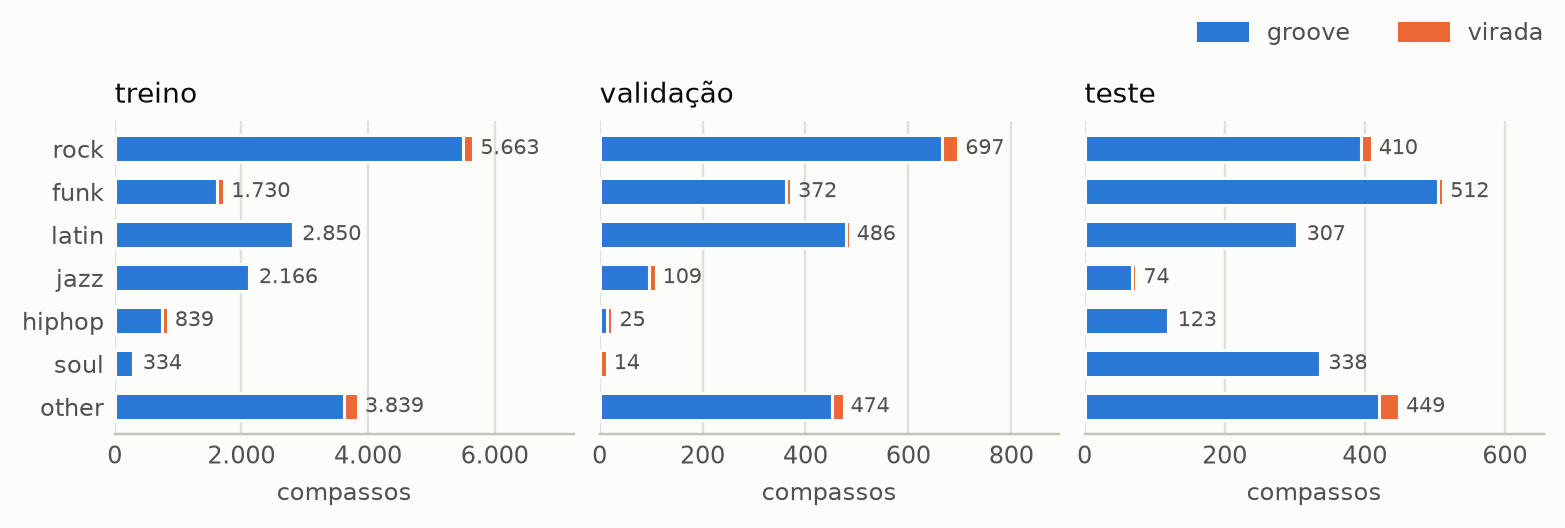

In [5]:
def bars_of(split, style, piece_type):
    return stats["bars"][split.value][style.value][piece_type.value]


figure, axes = plt.subplots(1, 3, figsize=(FULL_WIDTH, 2.3), sharey=True, layout="constrained")
rows = np.arange(len(STYLES))
for axis, split in zip(axes, Split):
    groove_bars = np.array([bars_of(split, style, PieceType.GROOVE) for style in STYLES])
    fill_bars = np.array([bars_of(split, style, PieceType.FILL) for style in STYLES])
    axis.barh(rows, groove_bars, height=BAR_HEIGHT, color=SERIES[0], edgecolor=SURFACE, linewidth=1)
    axis.barh(rows, fill_bars, left=groove_bars, height=BAR_HEIGHT, color=SERIES[1], edgecolor=SURFACE, linewidth=1)
    for row, total in zip(rows, groove_bars + fill_bars):
        axis.text(total, row, f" {thousands(total)}", va="center", fontsize=7, color=INK_SECONDARY)
    axis.set_xlim(0, (groove_bars + fill_bars).max() * 1.28)
    axis.xaxis.set_major_formatter(thousand_ticks)
    axis.grid(axis="y", visible=False)
    axis.spines["left"].set_visible(False)
    axis.set_title(SPLIT_LABELS[split])
    axis.set_xlabel("compassos")
axes[0].set_yticks(rows, [style.value for style in STYLES])
axes[0].invert_yaxis()
figure.legend(
    [Patch(color=SERIES[0]), Patch(color=SERIES[1])],
    [piece_type.value for piece_type in PieceType],
    loc="outside upper right",
    ncols=2,
)
save(figure, "compassos_por_estilo")

## 3. Tokens: vocabulário, tokens por compasso e comprimento das sequências

O vocabulário PerTok tem 158 tokens. A tabela agrupa o vocabulário por família e mostra quanto de cada família
aparece no treino. Peça (`PitchDrum`), velocity e desvio (`MicroTiming`) vêm a cada nota, com 27,8% dos tokens
cada; a posição (`Position`) vem uma vez por posição da grade e é compartilhada pelas notas simultâneas, com 15,2%.
O desvio é o custo de representar o microtiming.

In [6]:
train_split = TokenizedSplit.load(paths.split_file(Split.TRAIN))
train_tokens = np.concatenate(train_split.sequences)
families = pd.Series([tokenizer.token_of(token_id).split("_")[0] for token_id in range(tokenizer.vocab_size)])
used = pd.Series([tokenizer.token_of(int(token_id)).split("_")[0] for token_id in np.unique(train_tokens)])
token_counts = pd.Series(train_tokens).map(lambda token_id: tokenizer.token_of(int(token_id)).split("_")[0]).value_counts()

vocabulary = pd.DataFrame(
    {
        "no vocabulário": families.value_counts(),
        "usados no treino": used.value_counts(),
        "fração dos tokens de treino": (token_counts / token_counts.sum()).round(3),
    }
).fillna(0).astype({"no vocabulário": int, "usados no treino": int})
vocabulary = vocabulary.sort_values("fração dos tokens de treino", ascending=False)
vocabulary.loc["total"] = [tokenizer.vocab_size, int(np.unique(train_tokens).size), 1.0]
assert len(train_tokens) == stats["totals"]["train_tokens"]
vocabulary

,no vocabulário,usados no treino,fração dos tokens de treino
MicroTiming,17,17,0.278
Velocity,16,16,0.278
PitchDrum,16,9,0.278
Position,16,16,0.152
Bar,1,1,0.013
BOS,1,1,0.001
EOS,1,1,0.001
PAD,1,0,0.000
Pitch,89,0,0.000
total,158,61,1.000


O comprimento das sequências separa os dois tipos: o groove mediano tem 24 compassos, e 69% dos grooves passam do
contexto de 768 tokens; das 647 viradas, só uma passa (mediana de 1 compasso). Os tokens por compasso variam com a densidade do
estilo.

In [7]:
lengths = pd.DataFrame(
    [
        {
            "tipo": piece.type.value,
            "estilo": piece.style.value,
            "tokens": piece.n_tokens,
            "compassos": piece.n_bars,
            "tokens por compasso": (piece.n_tokens - 2) / piece.n_bars,
        }
        for piece in pieces
    ]
)
context = config.data.context_length
length_summary = lengths.groupby("tipo").agg(
    performances=("tokens", "size"),
    tokens_mediana=("tokens", "median"),
    tokens_máximo=("tokens", "max"),
    compassos_mediana=("compassos", "median"),
    acima_do_contexto=("tokens", lambda tokens: int((tokens > context).sum())),
)
per_style_density = (
    lengths[lengths["tipo"] == PieceType.GROOVE.value]
    .groupby("estilo")["tokens por compasso"]
    .describe()[["count", "mean", "50%", "min", "max"]]
    .reindex(style_order)
    .round(1)
)
print(f"tokens por compasso (todas as performances): {decimal(tokens_per_bar)}; contexto: {context} tokens")
display(length_summary.round(2))
per_style_density

tokens por compasso (todas as performances): 71,54; contexto: 768 tokens


,performances,tokens_mediana,tokens_máximo,compassos_mediana,acima_do_contexto
tipo,,,,,
groove,491,1597.0,40146,24.0,341
virada,647,62.0,869,1.0,1


,count,mean,50%,min,max
estilo,,,,,
rock,204.0,58.5,58.5,11.0,116.0
funk,53.0,75.9,74.2,40.8,121.1
latin,48.0,90.3,95.7,40.3,123.5
jazz,48.0,51.6,48.9,13.5,95.6
hiphop,34.0,70.3,66.2,31.5,108.8
soul,28.0,64.2,62.2,45.5,97.2
other,76.0,74.0,71.9,39.4,117.3


PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/tokens_por_sequencia.png')

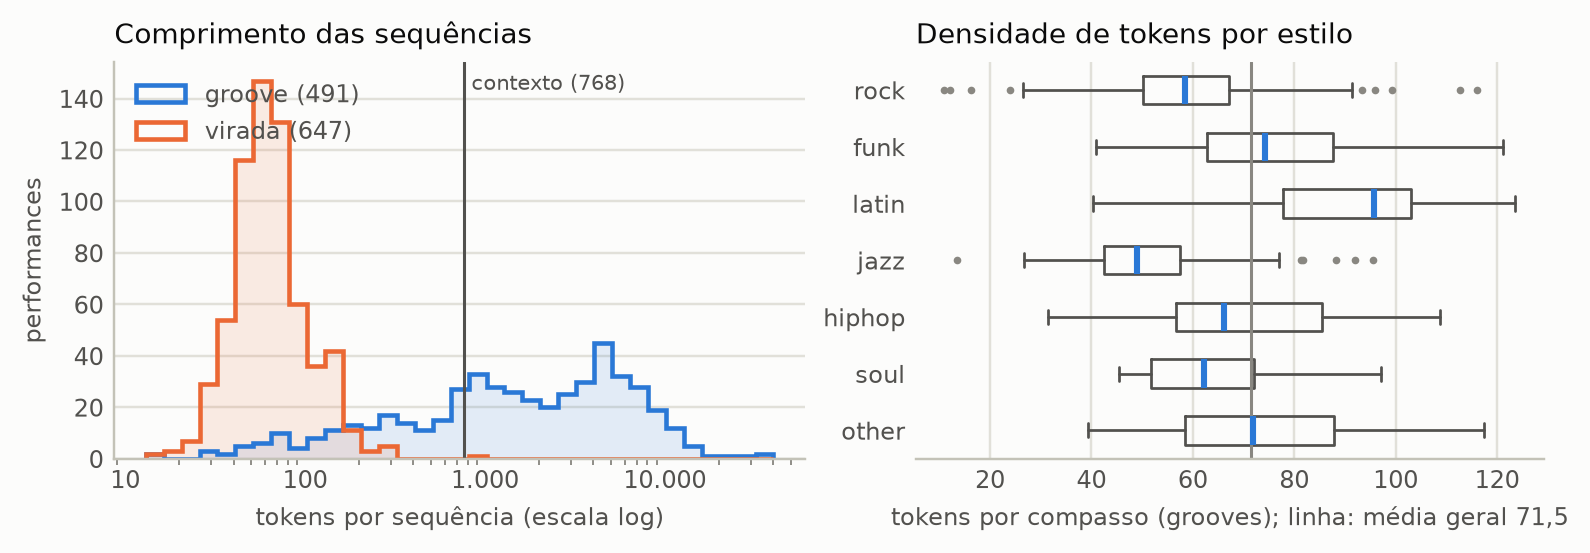

In [8]:
figure, (left, right) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.4), layout="constrained", width_ratios=[1.1, 1])
bins = np.geomspace(lengths["tokens"].min(), lengths["tokens"].max(), 36)
for piece_type, color in zip(PieceType, SERIES):
    values = lengths.loc[lengths["tipo"] == piece_type.value, "tokens"]
    left.hist(values, bins=bins, color=color, alpha=WASH_ALPHA, linewidth=0)
    left.hist(values, bins=bins, color=color, histtype="step", linewidth=1.5, label=f"{piece_type.value} ({len(values)})")
left.axvline(context, color=INK_SECONDARY, linewidth=1)
left.text(context, left.get_ylim()[1] * 0.97, f" contexto ({context})", color=INK_SECONDARY, fontsize=7, va="top")
left.set_xscale("log")
left.xaxis.set_major_formatter(thousand_ticks)
left.set_xlabel("tokens por sequência (escala log)")
left.set_ylabel("performances")
left.grid(axis="x", visible=False)
left.legend(loc="upper left")
left.set_title("Comprimento das sequências")

groove_density = [
    lengths.loc[(lengths["tipo"] == PieceType.GROOVE.value) & (lengths["estilo"] == style.value), "tokens por compasso"]
    for style in STYLES
]
right.boxplot(
    groove_density,
    orientation="horizontal",
    widths=0.5,
    showfliers=True,
    medianprops={"color": SERIES[0], "linewidth": 2},
    boxprops={"color": INK_SECONDARY, "linewidth": 0.9},
    whiskerprops={"color": INK_SECONDARY, "linewidth": 0.9},
    capprops={"color": INK_SECONDARY, "linewidth": 0.9},
    flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": INK_MUTED, "markeredgewidth": 0},
)
right.axvline(tokens_per_bar, color=INK_MUTED, linewidth=1)
right.set_yticks(range(1, len(STYLES) + 1), [style.value for style in STYLES])
right.invert_yaxis()
right.grid(axis="y", visible=False)
right.spines["left"].set_visible(False)
right.set_xlabel(f"tokens por compasso (grooves); linha: média geral {decimal(tokens_per_bar, 1)}")
right.set_title("Densidade de tokens por estilo")
save(figure, "tokens_por_sequencia")

## 4. BPM por estilo

Cada ponto é um groove de treino; o traço azul é o BPM mediano do estilo, o mesmo do `stats.json`, que o áudio usa
para todos os sistemas (D15). O jazz é o mais rápido (124) e o hiphop o mais lento (92).

In [9]:
bpm_by_style = {style: np.array([p.bpm for p in train_grooves if p.style is style]) for style in EVALUATED}
bpm_table = pd.DataFrame(
    {
        style.value: {
            "grooves": len(values),
            "mediana": float(np.median(values)),
            "p25": float(np.percentile(values, 25)),
            "p75": float(np.percentile(values, 75)),
            "mín": int(values.min()),
            "máx": int(values.max()),
            "stats.json": float(stats["median_bpm"][style.value]),
        }
        for style, values in bpm_by_style.items()
    }
).T
assert (bpm_table["mediana"] == bpm_table["stats.json"]).all()
bpm_table

,grooves,mediana,p25,p75,mín,máx,stats.json
rock,167.0,105.0,95.0,120.0,50.0,200.0,105.0
funk,31.0,100.0,92.0,101.0,80.0,117.0,100.0
latin,36.0,108.0,95.0,118.5,84.0,158.0,108.0
jazz,39.0,124.0,118.0,181.0,88.0,290.0,124.0
hiphop,26.0,92.0,86.0,100.0,67.0,140.0,92.0
soul,10.0,104.5,99.5,105.0,96.0,148.0,104.5


PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/bpm_por_estilo.png')

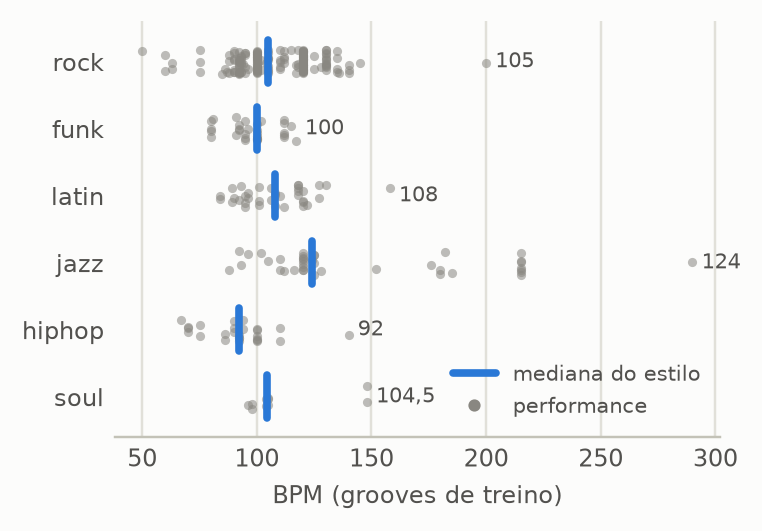

In [10]:
figure, axis = plt.subplots(figsize=(COLUMN_WIDTH, 2.3), layout="constrained")
jitter = np.random.default_rng(config.seed)
for row, (style, values) in enumerate(bpm_by_style.items()):
    offsets = jitter.uniform(-0.18, 0.18, size=values.size)
    axis.scatter(values, row + offsets, s=9, color=INK_MUTED, alpha=0.55, linewidths=0)
    median_bpm = float(np.median(values))
    axis.plot([median_bpm, median_bpm], [row - 0.32, row + 0.32], color=SERIES[0], linewidth=2.5)
    axis.text(values.max() + 4, row, f"{decimal(median_bpm, 1).removesuffix(',0')}", va="center", fontsize=7, color=INK_SECONDARY)
axis.set_yticks(range(len(bpm_by_style)), [style.value for style in bpm_by_style])
axis.invert_yaxis()
axis.grid(axis="y", visible=False)
axis.spines["left"].set_visible(False)
axis.set_xlabel("BPM (grooves de treino)")
axis.legend(
    [Line2D([], [], color=SERIES[0], linewidth=2.5), Line2D([], [], marker="o", linestyle="", color=INK_MUTED, markersize=3)],
    ["mediana do estilo", "performance"],
    loc="lower right",
    fontsize=7,
)
save(figure, "bpm_por_estilo")

## 5. Desbalanceamento e amostragem ponderada (D11)

**Antes** é a fração de janelas que cada estilo receberia num sorteio uniforme por compasso de treino (grooves e
viradas). **Depois** é a fração medida em 20 mil sorteios do próprio `TrainingWindows`, com peso proporcional a
1/√(compassos do estilo) e o estilo nulo do CFG em 20% das janelas. Entre as janelas com estilo, o soul passa de
1,9% para 5,6% (4,5% de todas as janelas), e o rock cai de 32,5% para 23,5%; o sorteio medido bate com o peso
esperado a menos de 0,5 ponto.

In [11]:
corpus = Corpus.load(paths, Split.TRAIN)
bars_per_style = {style: 0 for style in STYLES}
for style, starts in zip(corpus.styles, corpus.bar_starts, strict=True):
    bars_per_style[style] += len(starts)
before = {style: bars / sum(bars_per_style.values()) for style, bars in bars_per_style.items()}
root_bars = {style: np.sqrt(bars) for style, bars in bars_per_style.items()}
expected = {style: value / sum(root_bars.values()) for style, value in root_bars.items()}

draws = 20_000
windows = TrainingWindows(corpus, tokenizer, config.data, seed=config.seed)
drawn = pd.Series([list(Style)[int(windows[index].styles[0])] for index in range(draws)]).value_counts()
null_share = drawn.get(Style.NULL, 0) / draws
after_all = {style: drawn.get(style, 0) / draws for style in STYLES}
after_styled = {style: share / (1 - null_share) for style, share in after_all.items()}

weighting = pd.DataFrame(
    {
        "compassos de treino": bars_per_style,
        "antes (uniforme por compasso)": before,
        "depois, esperado (∝ √compassos)": expected,
        "depois, medido (janelas com estilo)": after_styled,
        "depois, medido (todas as janelas)": after_all,
    }
)
weighting.index = [style.value for style in weighting.index]
weighting.loc["nulo (CFG)"] = [0, 0.0, 0.0, 0.0, null_share]
print(f"estilo nulo em {percent(null_share)} das janelas (config: {percent(config.data.null_style_probability, 0)})")
print(f"soul: {percent(before[Style.SOUL])} antes; {percent(after_all[Style.SOUL])} de todas as janelas depois; {percent(after_styled[Style.SOUL])} das que têm estilo")
assert abs(after_all[Style.SOUL] - 0.045) < 0.005
assert all(abs(after_styled[style] - expected[style]) < 0.005 for style in STYLES)
weighting.style.format({column: "{:.1%}" for column in weighting.columns[1:]})

estilo nulo em 20,2% das janelas (config: 20%)
soul: 1,9% antes; 4,5% de todas as janelas depois; 5,6% das que têm estilo


,compassos de treino,antes (uniforme por compasso),"depois, esperado (∝ √compassos)","depois, medido (janelas com estilo)","depois, medido (todas as janelas)"
rock,5663,32.5%,23.1%,23.5%,18.7%
funk,1730,9.9%,12.8%,12.5%,10.0%
latin,2850,16.4%,16.4%,16.4%,13.1%
jazz,2166,12.4%,14.3%,14.5%,11.6%
hiphop,839,4.8%,8.9%,8.9%,7.1%
soul,334,1.9%,5.6%,5.6%,4.5%
other,3839,22.0%,19.0%,18.6%,14.9%
nulo (CFG),0,0.0%,0.0%,0.0%,20.2%


PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/ponderacao_estilos.png')

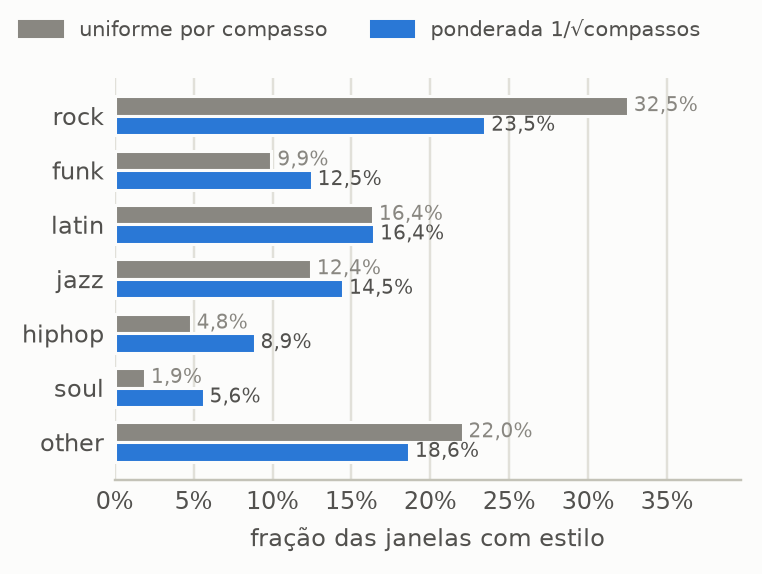

In [12]:
figure, axis = plt.subplots(figsize=(COLUMN_WIDTH, 2.5), layout="constrained")
rows = np.arange(len(STYLES))
height = 0.36
before_values = np.array([before[style] for style in STYLES])
after_values = np.array([after_styled[style] for style in STYLES])
axis.barh(rows - height / 2, before_values, height=height, color=INK_MUTED, edgecolor=SURFACE, linewidth=1)
axis.barh(rows + height / 2, after_values, height=height, color=SERIES[0], edgecolor=SURFACE, linewidth=1)
for row, (old, new) in enumerate(zip(before_values, after_values)):
    axis.text(old, row - height / 2, f" {percent(old)}", va="center", fontsize=6.5, color=INK_MUTED)
    axis.text(new, row + height / 2, f" {percent(new)}", va="center", fontsize=6.5, color=INK_SECONDARY)
axis.set_yticks(rows, [style.value for style in STYLES])
axis.invert_yaxis()
axis.set_xlim(0, before_values.max() * 1.22)
axis.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{100 * value:.0f}%"))
axis.grid(axis="y", visible=False)
axis.spines["left"].set_visible(False)
axis.set_xlabel("fração das janelas com estilo")
figure.legend(
    [Patch(color=INK_MUTED), Patch(color=SERIES[0])],
    ["uniforme por compasso", "ponderada 1/√compassos"],
    loc="outside upper left",
    ncols=2,
    fontsize=7,
)
save(figure, "ponderacao_estilos")

## 6. Expressividade: desvio da semicolcheia e swing (treino)

Esta seção justifica o PerTok. Ela mede as performances de groove do treino nos 6 estilos avaliados com as
métricas de `drumgen.metrics`, em três versões da mesma bateria:

- **humano:** o MIDI cru com as 9 peças;
- **PerTok:** a sequência tokenizada de `train.npz`, decodificada;
- **quantizado:** a mesma sequência com todo `MicroTiming` trocado por `MicroTiming_0`.

O desvio é a distância do onset à semicolcheia mais próxima, em fração de semicolcheia (`BeatGrid.offsets`). O swing
do estilo é a mediana da posição dentro do tempo das notas com fração em [0,4; 0,8), juntando as notas do estilo
(§6.6). Os dois saem de `BeatGrid.swing`: sobre os onsets de cada performance e sobre os onsets do estilo
concatenados.

In [13]:
with paths.catalog_file.open(newline="") as file:
    catalog = {entry.id: entry for entry in (CatalogEntry.from_row(row) for row in csv.DictReader(file))}
train_pieces = {piece.id: piece for piece in train_grooves if piece.style in EVALUATED}

human = {style: [] for style in EVALUATED}
pertok = {style: [] for style in EVALUATED}
quantized = {style: [] for style in EVALUATED}
for piece_id, sequence in zip(train_split.piece_ids, train_split.sequences, strict=True):
    piece = train_pieces.get(piece_id)
    if piece is None:
        continue
    score = tokenizer.map_drums(ScoreTick(paths.raw_dir / catalog[piece_id].midi_filename))
    last_onset = max(note.time for track in score.tracks for note in track.notes)
    human[piece.style].append(DrumSample.from_score(score, last_onset // (BEATS_PER_BAR * score.ticks_per_quarter) + 1))
    pertok[piece.style].append(DrumSample.from_score(tokenizer.decode(sequence.tolist()), piece.n_bars))
    quantized[piece.style].append(DrumSample.from_score(tokenizer.decode(tokenizer.quantize(sequence.tolist())), piece.n_bars))

performance_swings = {style: [sample.grid.swing(sample.onsets) for sample in samples] for style, samples in human.items()}
print({style.value: len(samples) for style, samples in human.items()})

{'rock': 167, 'funk': 31, 'latin': 36, 'jazz': 39, 'hiphop': 26, 'soul': 10}


In [14]:
def pooled(samples, measure):
    return np.concatenate([measure(sample) for sample in samples])


def offsets_of(samples):
    return pooled(samples, lambda sample: sample.grid.offsets(sample.onsets))


def style_swing(samples):
    return samples[0].grid.swing(pooled(samples, lambda sample: sample.onsets))


def piece_swings(style):
    return np.array([value for value in performance_swings[style] if value is not None])


SPEC_SWING = {Style.JAZZ: 0.583, Style.ROCK: 0.535, Style.LATIN: 0.510, Style.FUNK: 0.508, Style.HIPHOP: 0.500, Style.SOUL: 0.488}
far_threshold = 0.15
human_offsets = {style: offsets_of(samples) for style, samples in human.items()}
all_offsets = np.concatenate(list(human_offsets.values()))

expressiveness = pd.DataFrame(
    {
        style.value: {
            "grooves": len(human[style]),
            "notas": human_offsets[style].size,
            "|desvio| médio": float(np.mean(np.abs(human_offsets[style]))),
            "|desvio| > 0,15": float(np.mean(np.abs(human_offsets[style]) > far_threshold)),
            "|desvio| PerTok": float(np.mean(np.abs(offsets_of(pertok[style])))),
            "swing humano": style_swing(human[style]),
            "swing PerTok": style_swing(pertok[style]),
            "swing quantizado": style_swing(quantized[style]),
            "swing mediano por performance": float(np.median(piece_swings(style))),
            "performances sem swing": len(performance_swings[style]) - piece_swings(style).size,
            "swing do spec §6.6": SPEC_SWING[style],
        }
        for style in EVALUATED
    }
).T
print(f"notas de groove de treino a mais de {decimal(far_threshold)} de semicolcheia da grade: {percent(np.mean(np.abs(all_offsets) > far_threshold))}")
print(f"maior diferença de swing humano × PerTok: {decimal((expressiveness['swing humano'] - expressiveness['swing PerTok']).abs().max(), 3)} do tempo")
expressiveness.round(3)

notas de groove de treino a mais de 0,15 de semicolcheia da grade: 50,3%
maior diferença de swing humano × PerTok: 0,008 do tempo


,grooves,notas,|desvio| médio,"|desvio| > 0,15",|desvio| PerTok,swing humano,swing PerTok,swing quantizado,swing mediano por performance,performances sem swing,swing do spec §6.6
rock,167.0,98303.0,0.183,0.514,0.182,0.538,0.546,0.5,0.531,1.0,0.535
funk,31.0,36102.0,0.149,0.400,0.149,0.502,0.500,0.5,0.498,0.0,0.508
latin,36.0,69726.0,0.177,0.500,0.178,0.506,0.500,0.5,0.509,0.0,0.510
jazz,39.0,31081.0,0.224,0.638,0.225,0.583,0.577,0.5,0.581,0.0,0.583
hiphop,26.0,14080.0,0.144,0.378,0.144,0.498,0.500,0.5,0.509,0.0,0.500
soul,10.0,5196.0,0.187,0.548,0.188,0.471,0.469,0.5,0.473,0.0,0.488


A tabela confirma a leitura do spec, com uma ressalva. O swing do jazz fica em 0,583 do tempo. O PerTok preserva o
swing de cada estilo dentro de um bin de microtiming (1/64 de tempo ≈ 0,016), e a versão quantizada o apaga (0,5
em todos os estilos). Medido só no treino, o soul dá 0,471 contra 0,488 da tabela de §6.6. Os demais estilos ficam
a até 0,01 da tabela, que foi medida nas 3 partições; isso é a decisão em aberto no registro de execução do spec.

PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/desvio_semicolcheia.png')

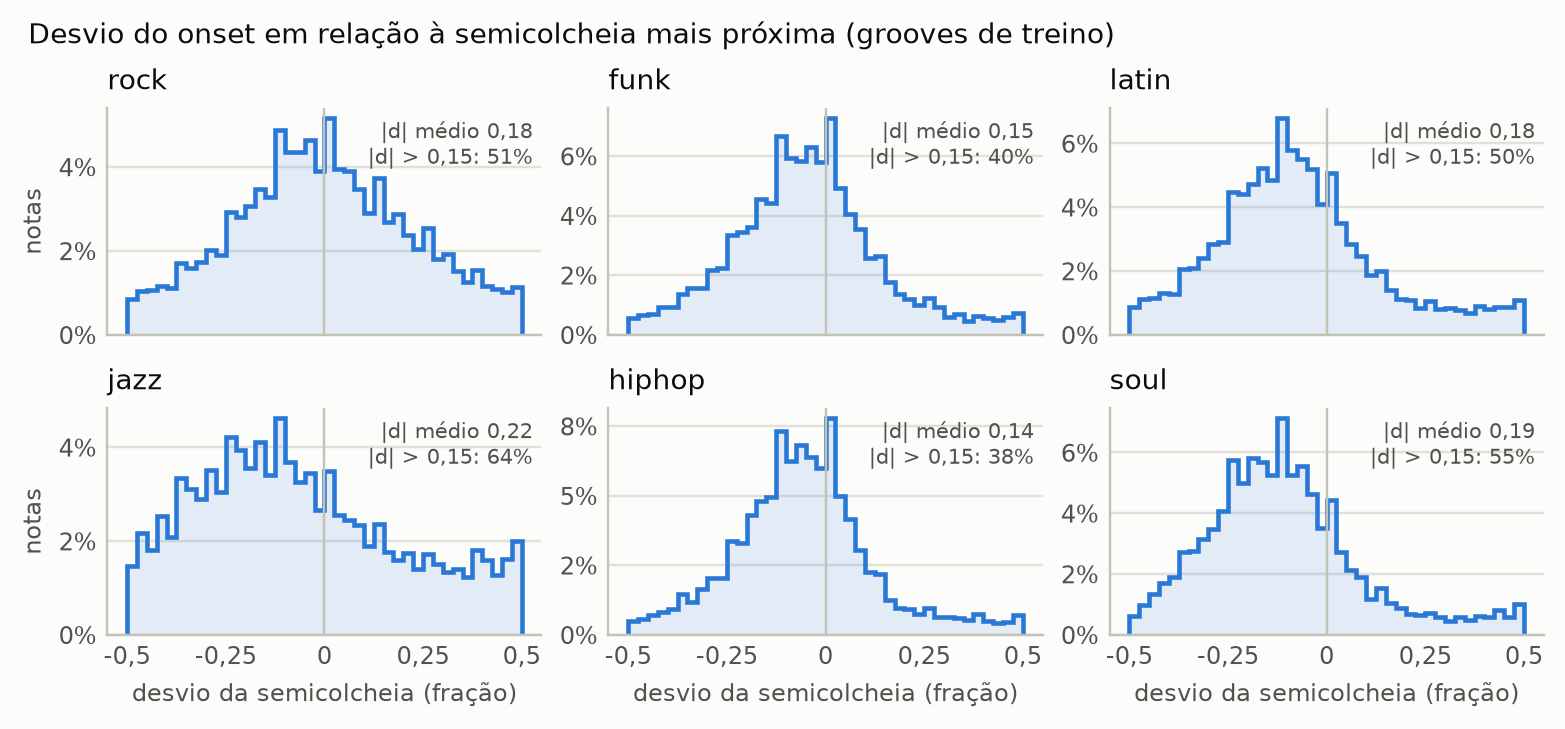

In [15]:
figure, axes = plt.subplots(2, 3, figsize=(FULL_WIDTH, 3.2), sharex=True, layout="constrained")
offset_bins = np.linspace(-0.5, 0.5, 41)
for axis, style in zip(axes.flat, EVALUATED):
    values = human_offsets[style]
    weights = np.full(values.size, 1 / values.size)
    axis.hist(values, bins=offset_bins, weights=weights, color=SERIES[0], alpha=WASH_ALPHA, linewidth=0)
    axis.hist(values, bins=offset_bins, weights=weights, color=SERIES[0], histtype="step", linewidth=1.5)
    axis.axvline(0, color=BASELINE, linewidth=0.8)
    axis.set_title(style.value)
    axis.text(
        0.98,
        0.95,
        f"|d| médio {decimal(float(np.mean(np.abs(values))))}\n|d| > 0,15: {percent(np.mean(np.abs(values) > far_threshold), 0)}",
        transform=axis.transAxes,
        ha="right",
        va="top",
        fontsize=7,
        color=INK_SECONDARY,
    )
    axis.grid(axis="x", visible=False)
    axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{100 * value:.0f}%"))
    axis.xaxis.set_major_formatter(comma_ticks)
for axis in axes[-1]:
    axis.set_xlabel("desvio da semicolcheia (fração)")
for axis in axes[:, 0]:
    axis.set_ylabel("notas")
figure.suptitle("Desvio do onset em relação à semicolcheia mais próxima (grooves de treino)", x=0.01, ha="left", fontsize=9, color=INK)
save(figure, "desvio_semicolcheia")

PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/swing_por_estilo.png')

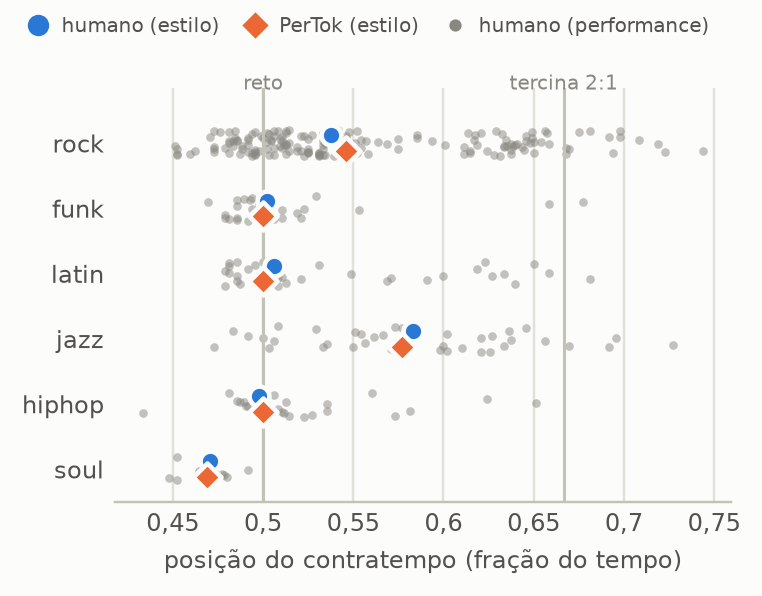

In [16]:
figure, axis = plt.subplots(figsize=(COLUMN_WIDTH, 2.6), layout="constrained")
jitter = np.random.default_rng(config.seed)
for row, style in enumerate(EVALUATED):
    swings = piece_swings(style)
    axis.scatter(swings, row + jitter.uniform(-0.2, 0.2, size=swings.size), s=8, color=INK_MUTED, alpha=0.5, linewidths=0)
    axis.scatter(style_swing(human[style]), row - 0.12, s=42, color=SERIES[0], edgecolors=SURFACE, linewidths=1.5, zorder=3)
    axis.scatter(style_swing(pertok[style]), row + 0.12, s=42, marker="D", color=SERIES[1], edgecolors=SURFACE, linewidths=1.5, zorder=3)
straight, triplet = 0.5, 2 / 3
for position, label in ((straight, "reto"), (triplet, "tercina 2:1")):
    axis.axvline(position, color=BASELINE, linewidth=1, zorder=1)
    axis.text(position, -0.75, label, ha="center", va="bottom", fontsize=6.5, color=INK_MUTED)
axis.set_yticks(range(len(EVALUATED)), [style.value for style in EVALUATED])
axis.set_ylim(len(EVALUATED) - 0.5, -0.85)
axis.grid(axis="y", visible=False)
axis.spines["left"].set_visible(False)
axis.xaxis.set_major_formatter(comma_ticks)
axis.set_xlabel("posição do contratempo (fração do tempo)")
figure.legend(
    [
        Line2D([], [], marker="o", linestyle="", color=SERIES[0], markersize=6),
        Line2D([], [], marker="D", linestyle="", color=SERIES[1], markersize=5),
        Line2D([], [], marker="o", linestyle="", color=INK_MUTED, markersize=3),
    ],
    ["humano (estilo)", "PerTok (estilo)", "humano (performance)"],
    loc="outside upper left",
    ncols=3,
    fontsize=6.5,
    handletextpad=0.2,
    columnspacing=0.8,
)
save(figure, "swing_por_estilo")

## 7. Velocity e perfil por posição da semicolcheia (treino)

A distribuição de velocity por estilo mostra a dinâmica que o PerTok guarda em 16 níveis: de 17% a 30% das notas
ficam abaixo de 40 (ghost notes), e de 8% (soul) a 21% (hiphop) saturam em 127. O perfil por posição
agrupa as notas pelas 4 semicolcheias do tempo (1, e, &, a), como o KL de timing e de velocity da avaliação (D7). O
desvio médio mostra onde cada estilo atrasa ou adianta, e a velocity média mostra os acentos.

In [17]:
velocities = {style: pooled(samples, lambda sample: sample.velocities) for style, samples in human.items()}
velocity_table = pd.DataFrame(
    {
        style.value: {
            "notas": values.size,
            "mediana": float(np.median(values)),
            "p10": float(np.percentile(values, 10)),
            "p90": float(np.percentile(values, 90)),
            "abaixo de 40 (ghost)": float(np.mean(values < 40)),
            "em 127": float(np.mean(values >= 127)),
        }
        for style, values in velocities.items()
    }
).T
velocity_table.round(2)

,notas,mediana,p10,p90,abaixo de 40 (ghost),em 127
rock,98303.0,69.0,28.0,127.0,0.18,0.15
funk,36102.0,58.0,21.0,127.0,0.30,0.16
latin,69726.0,55.0,19.0,121.0,0.30,0.09
jazz,31081.0,64.0,32.0,127.0,0.17,0.11
hiphop,14080.0,70.0,25.0,127.0,0.22,0.21
soul,5196.0,56.0,19.0,121.0,0.29,0.08


PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/velocity_por_estilo.png')

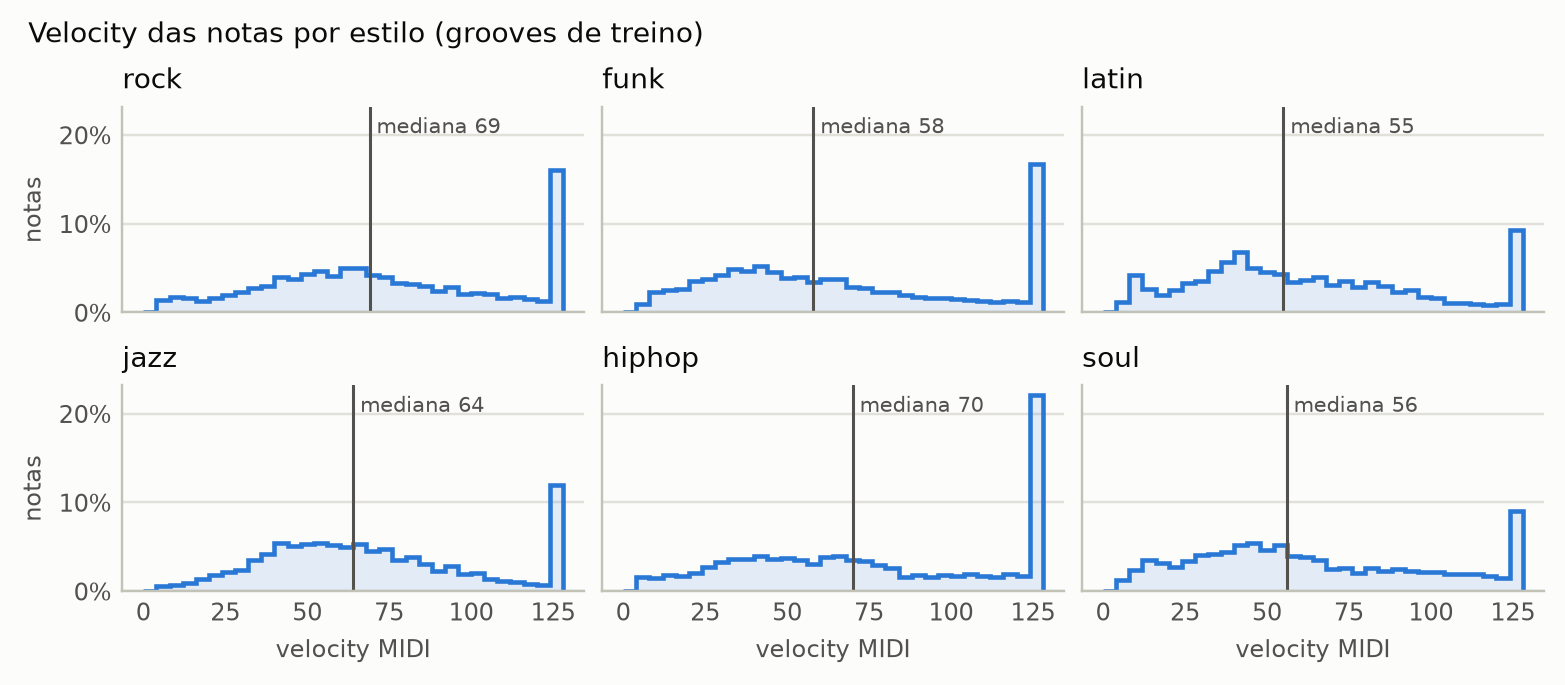

In [18]:
figure, axes = plt.subplots(2, 3, figsize=(FULL_WIDTH, 3.0), sharex=True, sharey=True, layout="constrained")
velocity_bins = np.linspace(0, 128, 33)
for axis, style in zip(axes.flat, EVALUATED):
    values = velocities[style]
    weights = np.full(values.size, 1 / values.size)
    axis.hist(values, bins=velocity_bins, weights=weights, color=SERIES[0], alpha=WASH_ALPHA, linewidth=0)
    axis.hist(values, bins=velocity_bins, weights=weights, color=SERIES[0], histtype="step", linewidth=1.5)
    median_velocity = float(np.median(values))
    axis.axvline(median_velocity, color=INK_SECONDARY, linewidth=1)
    axis.text(median_velocity, 0.95, f" mediana {median_velocity:.0f}", transform=axis.get_xaxis_transform(), fontsize=7, color=INK_SECONDARY, va="top")
    axis.set_title(style.value)
    axis.grid(axis="x", visible=False)
    axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{100 * value:.0f}%"))
for axis in axes[-1]:
    axis.set_xlabel("velocity MIDI")
for axis in axes[:, 0]:
    axis.set_ylabel("notas")
figure.suptitle("Velocity das notas por estilo (grooves de treino)", x=0.01, ha="left", fontsize=9, color=INK)
save(figure, "velocity_por_estilo")

In [19]:
profiles = {style: PositionalProfile.of(samples) for style, samples in human.items()}
position_labels = ["1", "e", "&", "a"]
mean_offset = np.array([[float(np.mean(group)) for group in profiles[style].offsets] for style in EVALUATED])
mean_velocity = np.array([[float(np.mean(group)) for group in profiles[style].velocities] for style in EVALUATED])
note_share = np.array([[group.size for group in profiles[style].offsets] for style in EVALUATED])
note_share = note_share / note_share.sum(axis=1, keepdims=True)
assert SIXTEENTHS_PER_BEAT == len(position_labels)

profile_table = pd.concat(
    {
        "desvio médio": pd.DataFrame(mean_offset, index=style_order[: len(EVALUATED)], columns=position_labels),
        "velocity média": pd.DataFrame(mean_velocity, index=style_order[: len(EVALUATED)], columns=position_labels),
        "fração das notas": pd.DataFrame(note_share, index=style_order[: len(EVALUATED)], columns=position_labels),
    },
    axis=1,
)
profile_table.round(3)

desvio médio                      velocity média                  \
                  1      e      &      a              1       e       &   
rock         -0.025  0.058  0.008 -0.026         84.601  57.501  70.020   
funk         -0.082  0.014 -0.097  0.034         80.747  51.662  66.562   
latin        -0.068 -0.036 -0.087 -0.099         64.646  54.821  61.200   
jazz         -0.136  0.022  0.018 -0.032         75.555  54.551  69.293   
hiphop       -0.083 -0.015 -0.080  0.019         92.384  53.565  74.719   
soul         -0.145  0.077 -0.162  0.063         73.304  43.378  56.604   

               fração das notas                       
             a                1      e      &      a  
rock    60.913            0.432  0.123  0.283  0.162  
funk    50.424            0.378  0.156  0.274  0.193  
latin   60.692            0.363  0.165  0.297  0.174  
jazz    62.304            0.449  0.106  0.241  0.204  
hiphop  50.561            0.397  0.151  0.303  0.150  
soul    49.143            0.507  0.088  0.301  0.104

PosixPath('/home/vinicius/ufmg/ia-musica/tp2/results/dataset/perfil_por_posicao.png')

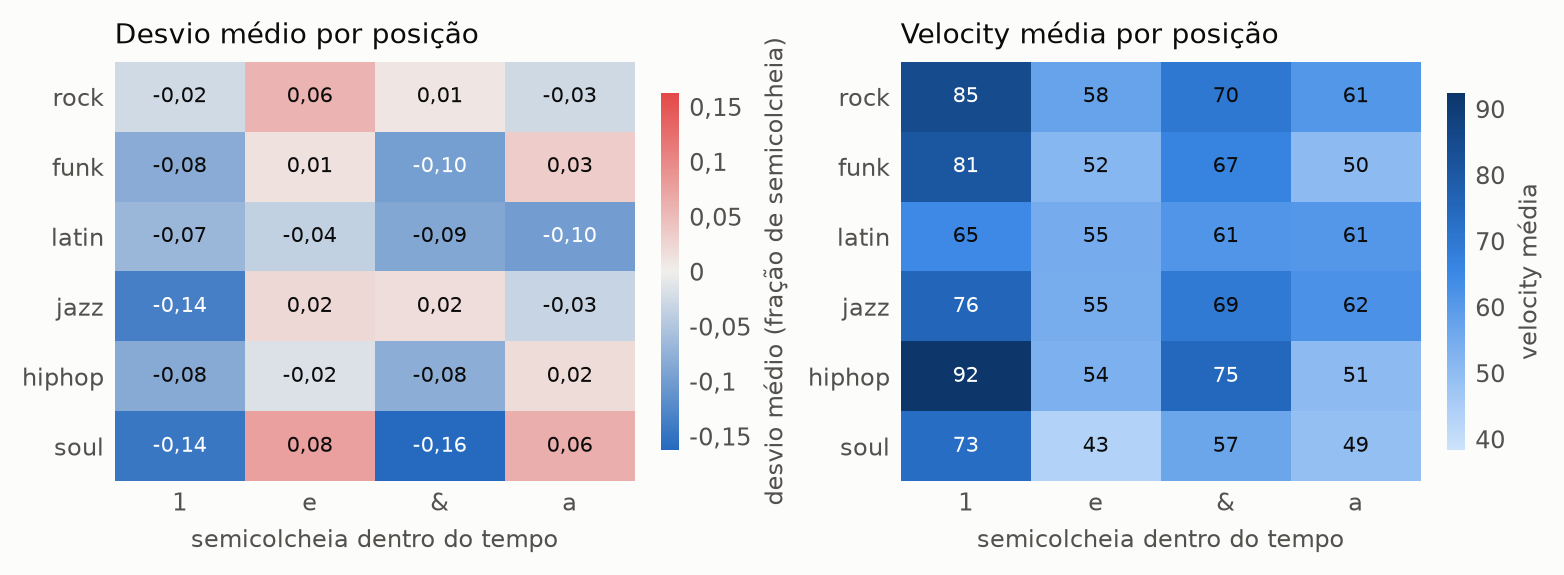

In [20]:
figure, (left, right) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.5), layout="constrained")
limit = float(np.abs(mean_offset).max())
panels = (
    (left, mean_offset, LinearSegmentedColormap.from_list("divergente", DIVERGING), TwoSlopeNorm(0.0, -limit, limit), lambda v: decimal(v), "desvio médio (fração de semicolcheia)", "Desvio médio por posição"),
    (right, mean_velocity, LinearSegmentedColormap.from_list("sequencial", SEQUENTIAL_RAMP), Normalize(mean_velocity.min() - 5, mean_velocity.max()), lambda v: f"{v:.0f}", "velocity média", "Velocity média por posição"),
)
for axis, values, color_map, norm, label, bar_label, title in panels:
    image = axis.imshow(values, cmap=color_map, norm=norm, aspect="auto")
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            shade = abs(norm(values[row, column]) - 0.5) * 2 if isinstance(norm, TwoSlopeNorm) else norm(values[row, column])
            axis.text(column, row, label(values[row, column]), ha="center", va="center", fontsize=7, color="#ffffff" if shade > 0.6 else INK)
    axis.set_xticks(range(len(position_labels)), position_labels)
    axis.set_yticks(range(len(EVALUATED)), [style.value for style in EVALUATED])
    axis.set_xlabel("semicolcheia dentro do tempo")
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_visible(False)
    axis.set_title(title)
    colorbar = figure.colorbar(image, ax=axis, shrink=0.85)
    colorbar.set_label(bar_label, color=INK_SECONDARY)
    colorbar.outline.set_visible(False)
    colorbar.ax.tick_params(length=0)
    colorbar.ax.yaxis.set_major_formatter(comma_ticks)
save(figure, "perfil_por_posicao")

## 8. Figuras gravadas

As figuras ficam em `results/dataset/`, todas bem abaixo do limite de 5 MB por arquivo versionado (invariante 5).

In [21]:
saved = pd.DataFrame(
    [(path.name, round(path.stat().st_size / 1024, 1)) for path in sorted(figures_dir.glob("*.png"))],
    columns=["figura", "KB"],
).set_index("figura")
assert (saved["KB"] < 5 * 1024).all()
saved

,KB
figura,
bpm_por_estilo.png,45.4
compassos_por_estilo.png,59.4
desvio_semicolcheia.png,125.2
perfil_por_posicao.png,108.8
ponderacao_estilos.png,52.6
swing_por_estilo.png,55.9
tokens_por_sequencia.png,77.4
velocity_por_estilo.png,73.1
